# TP Fuzzy C-means : segmentation floue d'une image

Ce notebook applique Fuzzy C-means (FCM) à l'image de la Voie lactée, d'abord en niveaux de gris avec deux clusters comme le propose le sujet, puis avec trois clusters et sur l'image couleur.

L'algorithme lui-même est écrit dans `fcm.py`, fonction par fonction, dans l'ordre de l'annexe : `init_U` (étape 1), `update_centers` (étape 2), `update_U` (étape 3) et `fcm` pour la boucle complète avec le critère d'arrêt (étape 4). Ce notebook se contente d'appeler ces fonctions et d'afficher les résultats.

Les images du sujet sont dans `data/`.

Image niveaux de gris : (1024, 1024)   Image couleur : (1024, 1024, 3)


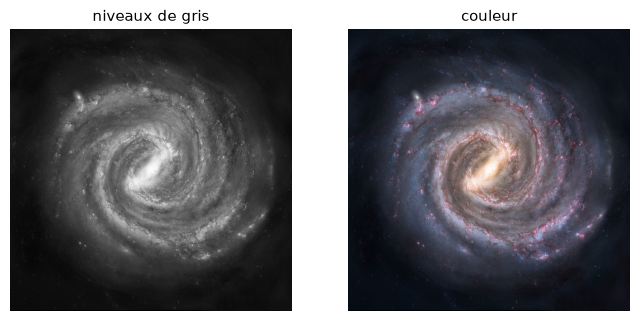

In [1]:
import time
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

from fcm import fcm, fcm_histogramme, kmeans, update_U

plt.rcParams.update({"font.size": 9})

gris = np.array(Image.open("data/milky-way-nvg.jpg"), dtype=np.float64)
coul = np.array(Image.open("data/milky-way.jpg"), dtype=np.float64)
H, W = gris.shape
print("Image niveaux de gris :", gris.shape, "  Image couleur :", coul.shape)

fig, ax = plt.subplots(1, 2, figsize=(8, 4))
ax[0].imshow(gris, cmap="gray"); ax[0].set_title("niveaux de gris")
ax[1].imshow(coul / 255); ax[1].set_title("couleur")
for a in ax:
    a.axis("off")
plt.show()

## Préparation des données

Chaque pixel est une donnée. En niveaux de gris, une donnée a un seul attribut (son niveau) ; en couleur, elle en a trois (R, G, B). On passe donc d'une image de 1024 × 1024 à un tableau de 1 048 576 lignes.

Deux petites fonctions servent dans tout le notebook. Le tirage aléatoire de U(0) donne les clusters dans un ordre quelconque : `trier` les range du plus sombre au plus clair, pour que le cluster 0 soit toujours le fond. `part_ambigus` compte les pixels dont le plus grand degré reste sous 0,7, c'est-à-dire ceux qui n'appartiennent nettement à aucun cluster.

In [2]:
Xg = gris.reshape(-1, 1)    # (1048576, 1)
Xc = coul.reshape(-1, 3)    # (1048576, 3)


def trier(U, C):
    ordre = np.argsort(C.sum(axis=1))
    return U[:, ordre], C[ordre]


def part_ambigus(U):
    degre_max = U.max(axis=1)
    return float((degre_max < 0.7).mean()) * 100


print("Xg :", Xg.shape, "  Xc :", Xc.shape)

Xg : (1048576, 1)   Xc : (1048576, 3)


## 1. Niveaux de gris, K = 2

Réglages de l'annexe : m = 2 et ε = 0,01. La fonction objectif $J_m$ doit diminuer à chaque itération.

12 itérations en 2.8 s
centres : [ 27.4 112.8] (fond, galaxie)
pixels attribués à la galaxie : 33.5 %
pixels ambigus (degré max < 0,7) : 8.8 %


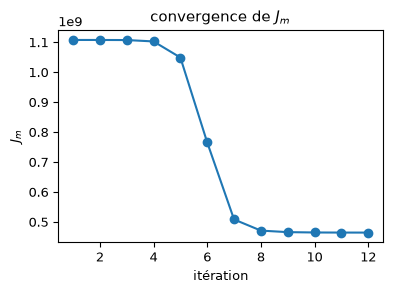

In [3]:
t = time.time()
U2, C2, it2, J2 = fcm(Xg, K=2, m=2.0, eps=0.01, seed=0)
duree = time.time() - t
U2, C2 = trier(U2, C2)

print(f"{it2} itérations en {duree:.1f} s")
print("centres :", C2.ravel().round(1), "(fond, galaxie)")
print(f"pixels attribués à la galaxie : {(U2[:, 1] > 0.5).mean() * 100:.1f} %")
print(f"pixels ambigus (degré max < 0,7) : {part_ambigus(U2):.1f} %")

plt.figure(figsize=(4, 3))
plt.plot(range(1, len(J2) + 1), J2, "o-")
plt.xlabel("itération"); plt.ylabel("$J_m$"); plt.title("convergence de $J_m$")
plt.tight_layout(); plt.show()

La heatmap montre le degré d'appartenance de chaque pixel au cluster clair. La segmentation dure affecte chaque pixel au cluster de degré maximal, comme le propose le sujet.

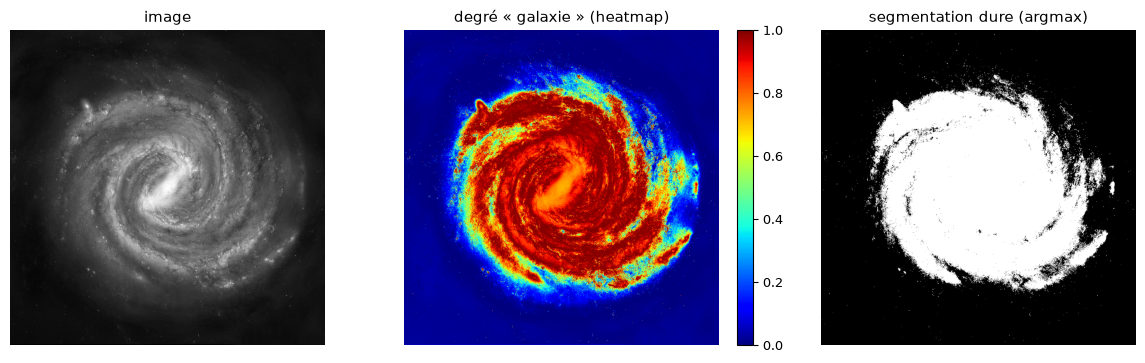

In [4]:
fig, ax = plt.subplots(1, 3, figsize=(12, 3.6))
ax[0].imshow(gris, cmap="gray"); ax[0].set_title("image")
im = ax[1].imshow(U2[:, 1].reshape(H, W), cmap="jet", vmin=0, vmax=1)
ax[1].set_title("degré « galaxie » (heatmap)")
fig.colorbar(im, ax=ax[1], fraction=0.046)
ax[2].imshow(U2.argmax(axis=1).reshape(H, W), cmap="gray")
ax[2].set_title("segmentation dure (argmax)")
for a in ax:
    a.axis("off")
plt.tight_layout(); plt.show()

Le bord des bras passe du bleu au rouge : ce sont les pixels ambigus, que la segmentation dure range d'un côté ou de l'autre sans nuance.

Le cœur de la galaxie, pourtant la zone la plus claire, n'est qu'à 0,7 environ. Un pixel à 255 est loin des deux centres, et le degré compare des distances relatives : $u = 1/(1 + (d_1/d_2)^2)$.

In [5]:
d_galaxie = abs(255 - C2[1, 0])
d_fond = abs(255 - C2[0, 0])
print(f"distance au centre galaxie : {d_galaxie:.0f}, au centre fond : {d_fond:.0f}")
print(f"degré « galaxie » d'un pixel à 255 : {1 / (1 + (d_galaxie / d_fond) ** 2):.2f}")

distance au centre galaxie : 142, au centre fond : 228
degré « galaxie » d'un pixel à 255 : 0.72


## 2. Effet de l'initialisation

FCM ne garantit qu'un minimum local. On relance avec cinq graines différentes pour voir si le résultat change.

In [6]:
for s in range(5):
    U, C, it, _ = fcm(Xg, K=2, m=2.0, eps=0.01, seed=s)
    print(f"graine {s} : {it:2d} itérations, centres {np.sort(C.ravel()).round(2)}")

graine 0 : 12 itérations, centres [ 27.44 112.78]


graine 1 : 11 itérations, centres [ 27.42 112.71]


graine 2 : 12 itérations, centres [ 27.43 112.74]


graine 3 : 12 itérations, centres [ 27.38 112.58]


graine 4 : 13 itérations, centres [ 27.41 112.67]


## 3. Effet du critère d'arrêt ε

L'exemple de l'annexe utilise ε = 0,3. On compare avec des valeurs plus petites.

In [7]:
for e in [0.3, 0.1, 0.01, 0.001]:
    U, C, it, _ = fcm(Xg, K=2, m=2.0, eps=e, seed=0)
    print(f"eps = {e:<6} : {it:2d} itérations, centres {np.sort(C.ravel()).round(2)}")

eps = 0.3    :  2 itérations, centres [56.93 57.16]


eps = 0.1    :  9 itérations, centres [ 26.73 110.16]


eps = 0.01   : 12 itérations, centres [ 27.44 112.78]


eps = 0.001  : 15 itérations, centres [ 27.55 113.11]


Avec ε = 0,3, l'algorithme s'arrête à la 2ᵉ itération avec deux centres presque confondus. La matrice de départ vaut environ 0,5 partout, la première mise à jour la change peu, et le test d'arrêt passe trop tôt.

## 4. Effet du coefficient de flou m

Pour chaque valeur de m, on trace le degré d'appartenance au cluster clair en fonction du niveau de gris. C'est la formule de l'étape 3 (`update_U`) appliquée aux 256 niveaux possibles.

m = 1.2 : 11 itérations, centres [ 29.1 113.1], pixels ambigus 1.5 %


m = 1.5 : 11 itérations, centres [ 28.6 113.4], pixels ambigus 4.5 %


m = 2.0 : 12 itérations, centres [ 27.4 112.8], pixels ambigus 8.8 %


m = 3.0 : 14 itérations, centres [ 25.6 110.9], pixels ambigus 18.9 %


m = 5.0 : 21 itérations, centres [ 24.3 109.4], pixels ambigus 38.6 %


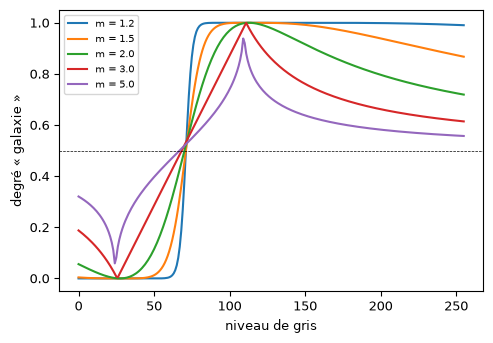

In [8]:
niveaux = np.arange(256).reshape(-1, 1)
plt.figure(figsize=(5, 3.5))
for m in [1.2, 1.5, 2.0, 3.0, 5.0]:
    U, C, it, _ = fcm(Xg, K=2, m=m, eps=0.01, seed=0)
    U, C = trier(U, C)
    print(f"m = {m} : {it:2d} itérations, centres {C.ravel().round(1)}, "
          f"pixels ambigus {part_ambigus(U):.1f} %")
    plt.plot(niveaux, update_U(niveaux, C, m)[:, 1], label=f"m = {m}")
plt.axhline(0.5, color="k", lw=0.5, ls="--")
plt.xlabel("niveau de gris"); plt.ylabel("degré « galaxie »"); plt.legend(fontsize=7)
plt.tight_layout(); plt.show()

Plus m est petit, plus la courbe ressemble à une marche : on se rapproche de k-means. Plus m est grand, plus les degrés restent proches de 0,5 et plus la convergence est lente.

## 5. Comparaison avec k-means

Un k-means dur, écrit avec la même boucle mais une affectation à un seul cluster.

In [9]:
lab, Ck, itk = kmeans(Xg, K=2, seed=0)
clair_km = lab == np.argmax(Ck.ravel())
clair_fcm = U2[:, 1] > 0.5
print(f"k-means : {itk} itérations, centres {np.sort(Ck.ravel()).round(1)}")
print(f"accord avec la segmentation dure de FCM : {(clair_km == clair_fcm).mean() * 100:.2f} %")

k-means : 6 itérations, centres [ 29.1 112.4]
accord avec la segmentation dure de FCM : 100.00 %


Les deux segmentations dures sont identiques. Ce que FCM apporte ici, c'est le degré de confiance de chaque pixel.

## 6. Niveaux de gris, K = 3

28 itérations, centres [ 22.7  81.1 141.7], pixels ambigus 15.1 %


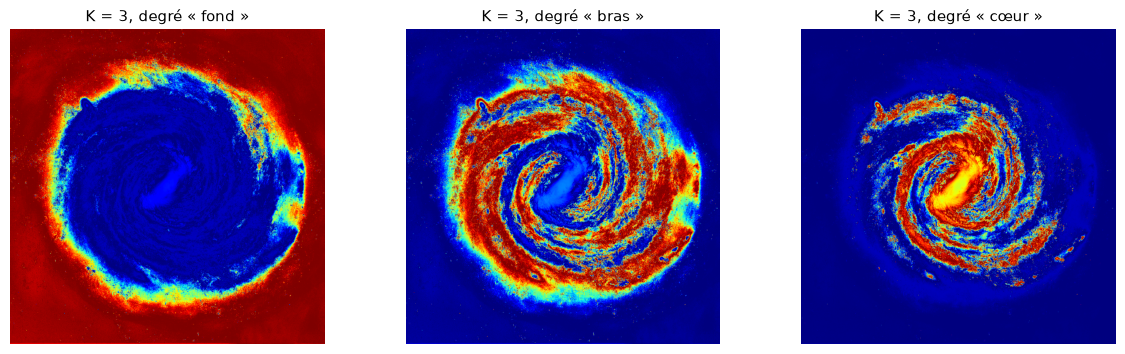

In [10]:
U3, C3, it3, _ = fcm(Xg, K=3, m=2.0, eps=0.01, seed=0)
U3, C3 = trier(U3, C3)
print(f"{it3} itérations, centres {C3.ravel().round(1)}, pixels ambigus {part_ambigus(U3):.1f} %")

noms = ["fond", "bras", "cœur"]
fig, ax = plt.subplots(1, 3, figsize=(12, 3.6))
for j in range(3):
    ax[j].imshow(U3[:, j].reshape(H, W), cmap="jet", vmin=0, vmax=1)
    ax[j].set_title(f"K = 3, degré « {noms[j]} »")
    ax[j].axis("off")
plt.tight_layout(); plt.show()

## 7. Image couleur, K = 4

Même algorithme, avec trois attributs par pixel. Ce calcul prend environ une demi-minute.

28 itérations en 27 s
centres RGB :
[[ 17.  21.  29.]
 [ 59.  60.  75.]
 [112. 103. 115.]
 [180. 160. 167.]]


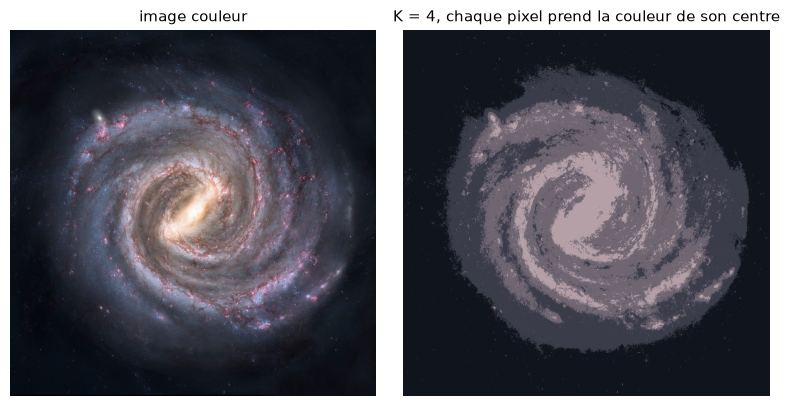

In [11]:
t = time.time()
Uc, Cc, itc, _ = fcm(Xc, K=4, m=2.0, eps=0.01, seed=0)
Uc, Cc = trier(Uc, Cc)
print(f"{itc} itérations en {time.time() - t:.0f} s")
print("centres RGB :")
print(Cc.round(0))

segmentation = Cc[Uc.argmax(axis=1)].reshape(H, W, 3) / 255
fig, ax = plt.subplots(1, 2, figsize=(8, 4))
ax[0].imshow(coul / 255); ax[0].set_title("image couleur")
ax[1].imshow(segmentation); ax[1].set_title("K = 4, chaque pixel prend la couleur de son centre")
for a in ax:
    a.axis("off")
plt.tight_layout(); plt.show()

Le découpage ressemble beaucoup à celui des niveaux de gris : en distance euclidienne sur (R, G, B), la luminosité l'emporte, et les petites régions roses ne forment pas de cluster.

## 8. α-coupes

Une α-coupe garde les pixels dont le degré « galaxie » est au moins α. On choisit la taille de la région après coup, sans relancer l'algorithme.

alpha = 0.3 : 37.9 % des pixels
alpha = 0.5 : 33.5 % des pixels
alpha = 0.7 : 29.0 % des pixels
alpha = 0.9 : 19.6 % des pixels


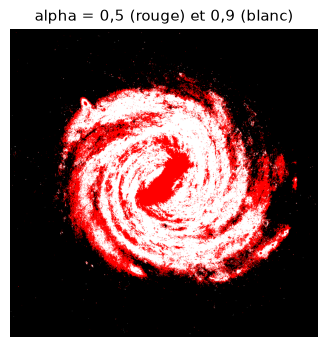

In [12]:
for a in [0.3, 0.5, 0.7, 0.9]:
    dans_la_coupe = U2[:, 1] >= a
    print(f"alpha = {a} : {dans_la_coupe.mean() * 100:.1f} % des pixels")

coupes = np.zeros((H, W, 3))
coupes[..., 0] = (U2[:, 1] >= 0.5).reshape(H, W)
coupes[..., 1] = (U2[:, 1] >= 0.9).reshape(H, W)
coupes[..., 2] = (U2[:, 1] >= 0.9).reshape(H, W)
plt.figure(figsize=(4, 4))
plt.imshow(coupes); plt.title("alpha = 0,5 (rouge) et 0,9 (blanc)"); plt.axis("off")
plt.show()

## 9. Accélération par histogramme

En niveaux de gris, il n'y a que 256 valeurs possibles et le degré d'un pixel ne dépend que de sa valeur. `fcm_histogramme` fait tourner FCM sur les niveaux présents, chacun pondéré par son nombre de pixels, puis recopie les degrés sur l'image.

In [13]:
t = time.time()
U, C, it, _ = fcm(Xg, K=2, m=2.0, eps=0.01, seed=0)
t_pixels = time.time() - t

t = time.time()
Uh, Ch, ith, _ = fcm_histogramme(Xg, K=2, m=2.0, eps=0.01, seed=0)
t_histo = time.time() - t
Uh, Ch = trier(Uh, Ch)

print(f"sur les pixels     : {t_pixels:.2f} s, centres {C2.ravel().round(2)}")
print(f"sur l'histogramme  : {t_histo:.3f} s, centres {Ch.ravel().round(2)}")
print(f"écart maximal sur les degrés : {np.abs(Uh - U2).max():.1e}")
print(f"segmentation dure identique pour {(Uh.argmax(1) == U2.argmax(1)).mean() * 100:.0f} % des pixels")
print(f"environ {t_pixels / t_histo:.0f} fois plus rapide")

sur les pixels     : 2.62 s, centres [ 27.44 112.78]
sur l'histogramme  : 0.028 s, centres [ 27.44 112.78]
écart maximal sur les degrés : 4.6e-05
segmentation dure identique pour 100 % des pixels
environ 94 fois plus rapide


## Bilan

Sur cette image, m = 2 et ε = 0,01 donnent une segmentation peu sensible au tirage initial et identique à k-means pour la décision dure. Les degrés d'appartenance localisent l'incertitude sur les bords des bras, et les α-coupes permettent d'en tirer une région plus ou moins large. FCM traite toutefois chaque pixel sans regarder ses voisins : les étoiles isolées du fond rejoignent la galaxie. Un terme spatial serait la suite logique.